Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

Libraries imported successfully


Load CSV

In [2]:
# Load dataset from the current notebook folder
df = pd.read_csv(
    "../data/clustering/bank_transactions.csv",
    parse_dates=["TransactionDate"]
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
df.head()

C:\Users\Admin\AppData\Local\Temp\ipykernel_17196\462667496.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(


Dataset loaded successfully
Dataset shape: (1048567, 9)

Columns:
['TransactionID', 'CustomerID', 'CustomerDOB', 'CustGender', 'CustLocation', 'CustAccountBalance', 'TransactionDate', 'TransactionTime', 'TransactionAmount (INR)']

First 5 rows:


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,10/1/94,F,JAMSHEDPUR,17819.05,2016-02-08,143207,25.0
1,T2,C2142763,4/4/57,M,JHAJJAR,2270.69,2016-02-08,141858,27999.0
2,T3,C4417068,26/11/96,F,MUMBAI,17874.44,2016-02-08,142712,459.0
3,T4,C5342380,14/9/73,F,MUMBAI,866503.21,2016-02-08,142714,2060.0
4,T5,C9031234,24/3/88,F,NAVI MUMBAI,6714.43,2016-02-08,181156,1762.5


Identify columns

In [3]:
# Standardize column names
data = df.copy()
data.columns = data.columns.str.strip().str.replace(" ", "_")

# Detect customer ID column
customer_id_column = None
for column in data.columns:
    if "customerid" in column.lower():
        customer_id_column = column
        break

# Detect transaction date column
transaction_date_column = None
for column in data.columns:
    if "transactiondate" in column.lower():
        transaction_date_column = column
        break

# Detect transaction amount column
transaction_amount_column = None
for column in data.columns:
    if "transactionamount" in column.lower():
        transaction_amount_column = column
        break

# Detect account balance column
account_balance_column = None
for column in data.columns:
    if "accountbalance" in column.lower():
        account_balance_column = column
        break

# Detect date of birth column
dob_column = None
for column in ["DOB", "CustomerDOB", "DateOfBirth", "CustDOB"]:
    if column in data.columns:
        dob_column = column
        break

print("Customer ID column:", customer_id_column)
print("Transaction date column:", transaction_date_column)
print("Transaction amount column:", transaction_amount_column)
print("Account balance column:", account_balance_column)
print("Date of birth column:", dob_column)

Customer ID column: CustomerID
Transaction date column: TransactionDate
Transaction amount column: TransactionAmount_(INR)
Account balance column: CustAccountBalance
Date of birth column: CustomerDOB


Clean data

In [4]:
# Remove exact duplicate rows
data = data.drop_duplicates()

# Remove rows with missing essential values
essential_columns = [
    customer_id_column,
    transaction_date_column,
    transaction_amount_column,
    account_balance_column
]

data = data.dropna(subset=essential_columns)

# Remove invalid financial records
data = data[
    (data[transaction_amount_column] > 0) &
    (data[account_balance_column] >= 0)
]

# Convert CustomerID to string
data[customer_id_column] = data[customer_id_column].astype(str)

# Reset index
data = data.reset_index(drop=True)

print("Shape after cleaning:", data.shape)
print("\nMissing values after cleaning:")
print(data.isnull().sum())

Shape after cleaning: (1045368, 9)

Missing values after cleaning:
TransactionID                 0
CustomerID                    0
CustomerDOB                3386
CustGender                 1100
CustLocation                151
CustAccountBalance            0
TransactionDate               0
TransactionTime               0
TransactionAmount_(INR)       0
dtype: int64


Feature Engineering

In [5]:
if dob_column is not None:
    # Convert DOB to datetime
    data[dob_column] = pd.to_datetime(
        data[dob_column],
        errors="coerce"
    )

    # Reference date for calculating age
    reference_date = data[transaction_date_column].max()

    # Calculate age in years
    data["Age"] = (
        (reference_date - data[dob_column]).dt.days / 365.25
    )

    # Keep realistic ages only
    data = data[
        (data["Age"] >= 18) &
        (data["Age"] <= 100)
    ]

    print("Age feature created successfully.")
else:
    print("No DOB column found. Age feature will not be created.")

print("\nCurrent columns:")
print(data.columns.tolist())

C:\Users\Admin\AppData\Local\Temp\ipykernel_17196\3462914764.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[dob_column] = pd.to_datetime(


Age feature created successfully.

Current columns:
['TransactionID', 'CustomerID', 'CustomerDOB', 'CustGender', 'CustLocation', 'CustAccountBalance', 'TransactionDate', 'TransactionTime', 'TransactionAmount_(INR)', 'Age']


----EDA----

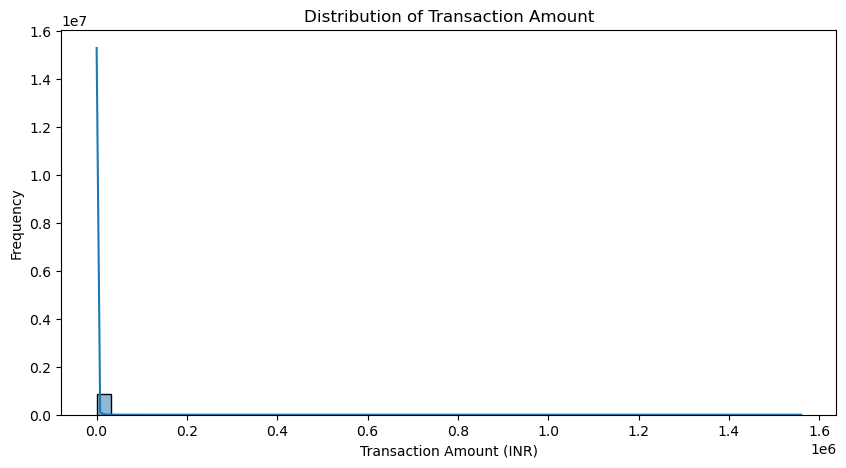

In [6]:
#Transaction Amount Distribution
plt.figure(figsize=(10, 5))
sns.histplot(data[transaction_amount_column], bins=50, kde=True)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount (INR)")
plt.ylabel("Frequency")
plt.show()

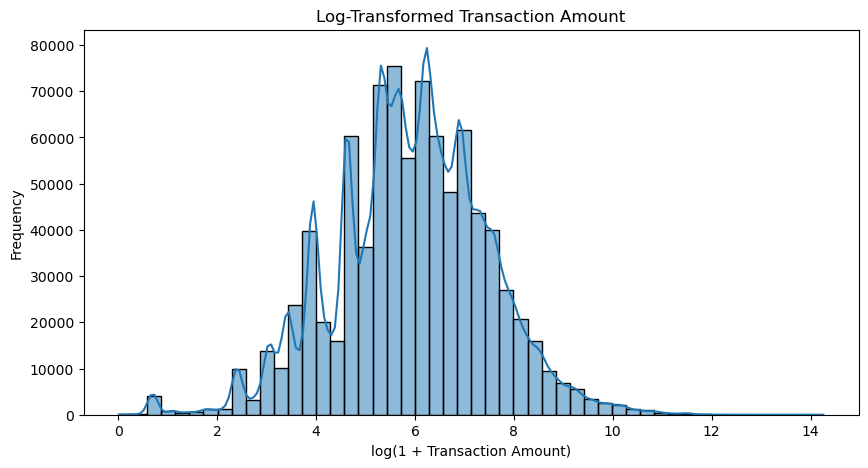

In [7]:
#Log-transformed Transaction Amount
plt.figure(figsize=(10, 5))
sns.histplot(
    np.log1p(data[transaction_amount_column]),
    bins=50,
    kde=True
)
plt.title("Log-Transformed Transaction Amount")
plt.xlabel("log(1 + Transaction Amount)")
plt.ylabel("Frequency")
plt.show()

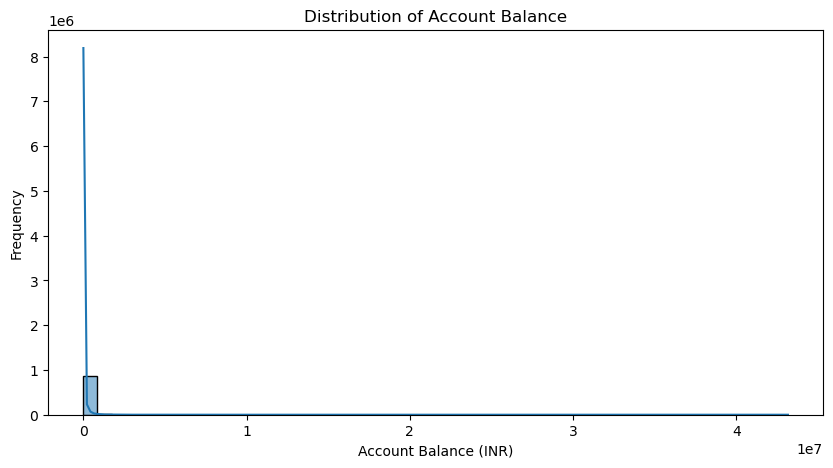

In [8]:
#Account balance distribution
plt.figure(figsize=(10, 5))
sns.histplot(data[account_balance_column], bins=50, kde=True)
plt.title("Distribution of Account Balance")
plt.xlabel("Account Balance (INR)")
plt.ylabel("Frequency")
plt.show()

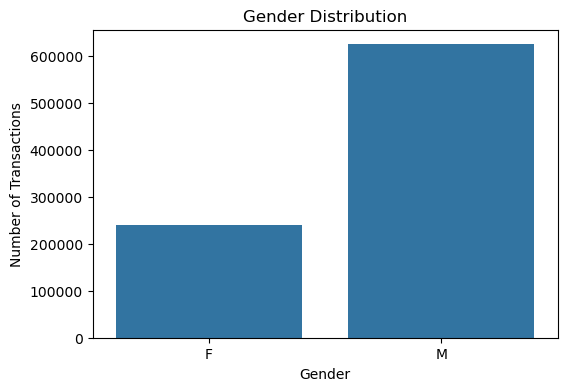

In [9]:
#Gender distribution
gender_column = None

for column in data.columns:
    if "gender" in column.lower():
        gender_column = column
        break

if gender_column is not None:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=gender_column, data=data)
    plt.title("Gender Distribution")
    plt.xlabel("Gender")
    plt.ylabel("Number of Transactions")
    plt.show()
else:
    print("No gender column found.")

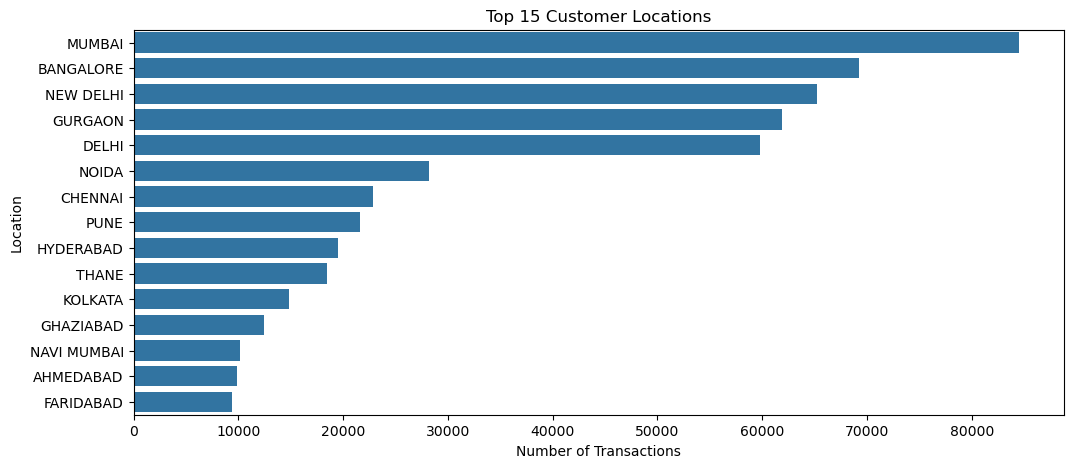

In [10]:
#Top Location
location_column = None

for column in data.columns:
    if "location" in column.lower():
        location_column = column
        break

if location_column is not None:
    top_locations = data[location_column].value_counts().head(15)

    plt.figure(figsize=(12, 5))
    sns.barplot(x=top_locations.values, y=top_locations.index)
    plt.title("Top 15 Customer Locations")
    plt.xlabel("Number of Transactions")
    plt.ylabel("Location")
    plt.show()
else:
    print("No location column found.")

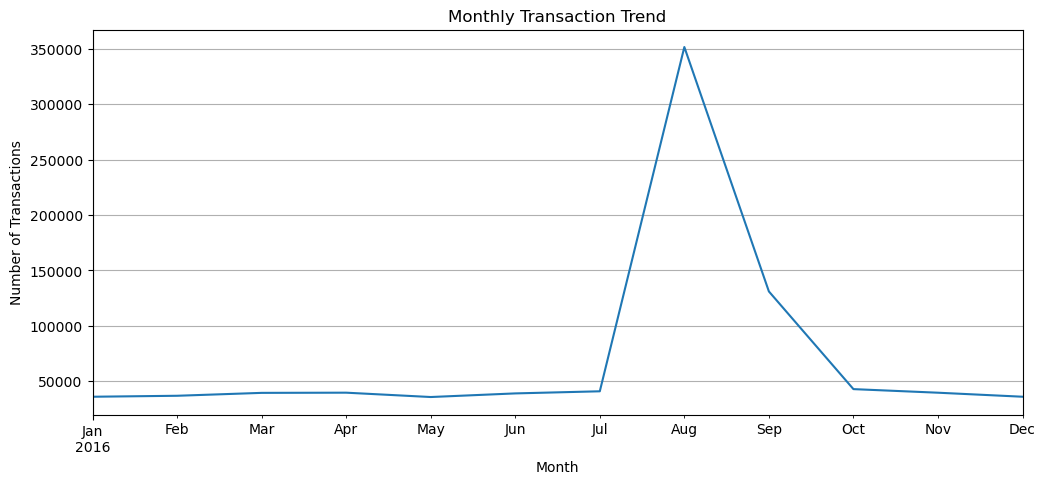

In [11]:
#Monthly-Transaction Trend
data["TransactionMonth"] = data[transaction_date_column].dt.to_period("M")

monthly_transactions = data.groupby("TransactionMonth").size()

plt.figure(figsize=(12, 5))
monthly_transactions.plot()
plt.title("Monthly Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.grid(True)
plt.show()

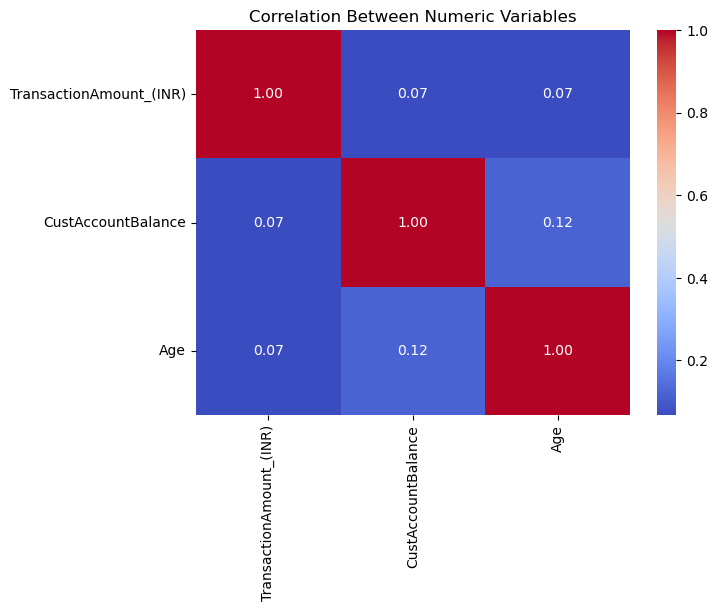

In [12]:
#Correlation-Heatmap
numeric_columns = [
    transaction_amount_column,
    account_balance_column
]

if "Age" in data.columns:
    numeric_columns.append("Age")

plt.figure(figsize=(7, 5))
sns.heatmap(
    data[numeric_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numeric Variables")
plt.show()

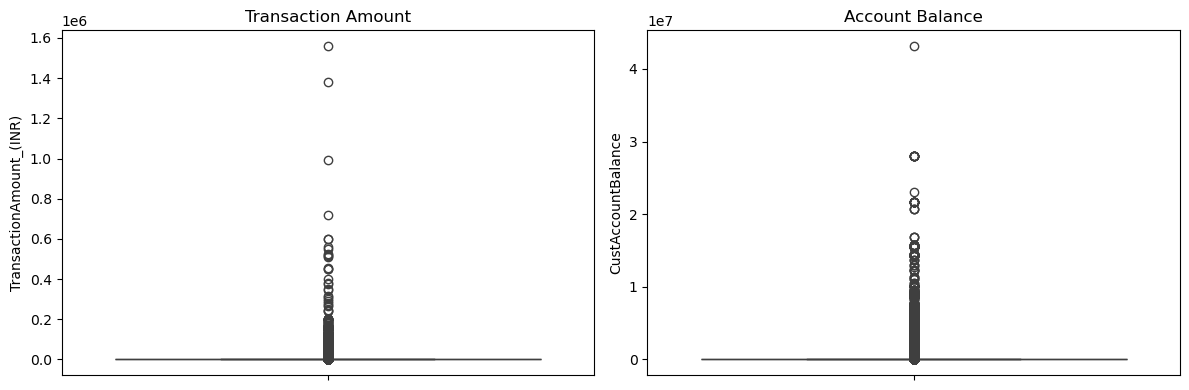

In [13]:
#Outlier-Visualisation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=data[transaction_amount_column])
plt.title("Transaction Amount")

plt.subplot(1, 2, 2)
sns.boxplot(y=data[account_balance_column])
plt.title("Account Balance")

plt.tight_layout()
plt.show()

-----Feature Engineering-----

In [14]:
# Reference date for recency calculation
snapshot_date = data[transaction_date_column].max() + pd.Timedelta(days=1)

# Create customer-level features
customer_features = data.groupby(customer_id_column).agg(
    Recency=(
        transaction_date_column,
        lambda x: (snapshot_date - x.max()).days
    ),
    Frequency=(transaction_date_column, "count"),
    Monetary=(transaction_amount_column, "sum"),
    AvgTransactionAmount=(transaction_amount_column, "mean"),
    MaxTransactionAmount=(transaction_amount_column, "max"),
    AvgAccountBalance=(account_balance_column, "mean"),
    MaxAccountBalance=(account_balance_column, "max")
).reset_index()

# Rename CustomerID column
customer_features = customer_features.rename(
    columns={customer_id_column: "CustomerID"}
)

# Derived feature: average spend per transaction
customer_features["AmountPerTransaction"] = (
    customer_features["Monetary"] /
    customer_features["Frequency"]
)

# Derived feature: balance relative to spending
customer_features["BalanceToSpendRatio"] = (
    customer_features["AvgAccountBalance"] /
    (customer_features["Monetary"] + 1)
)

# Add Age only if it exists
if "Age" in data.columns:
    age_features = data.groupby(customer_id_column)["Age"].mean().reset_index()
    age_features = age_features.rename(
        columns={customer_id_column: "CustomerID"}
    )

    customer_features = customer_features.merge(
        age_features,
        on="CustomerID",
        how="left"
    )

print("Customer-level dataset shape:", customer_features.shape)
customer_features.head()

Customer-level dataset shape: (751222, 11)


,CustomerID,Recency,Frequency,Monetary,AvgTransactionAmount,MaxTransactionAmount,AvgAccountBalance,MaxAccountBalance,AmountPerTransaction,BalanceToSpendRatio,Age
0,C1010011,75,2,5106.0,2553.0,4750.0,76340.635,120180.54,2553.0,14.948235,28.948665
1,C1010012,118,1,1499.0,1499.0,1499.0,24204.490,24204.49,1499.0,16.136327,22.368241
2,C1010014,155,2,1455.0,727.5,1205.0,100112.950,161848.76,727.5,68.758894,28.491444
3,C1010018,86,1,30.0,30.0,30.0,496.180,496.18,30.0,16.005806,26.532512
4,C1010028,103,1,557.0,557.0,557.0,296828.370,296828.37,557.0,531.950484,28.290212


---Select Clustering Features---

In [15]:
# Base clustering features
clustering_features = [
    "Recency",
    "Frequency",
    "Monetary",
    "AvgTransactionAmount",
    "MaxTransactionAmount",
    "AvgAccountBalance",
    "MaxAccountBalance",
    "AmountPerTransaction",
    "BalanceToSpendRatio"
]

# Add Age only if available
if "Age" in customer_features.columns:
    clustering_features.append("Age")

X = customer_features[clustering_features].copy()

print("Selected clustering features:")
print(clustering_features)

print("\nShape before preprocessing:")
print(X.shape)

Selected clustering features:
['Recency', 'Frequency', 'Monetary', 'AvgTransactionAmount', 'MaxTransactionAmount', 'AvgAccountBalance', 'MaxAccountBalance', 'AmountPerTransaction', 'BalanceToSpendRatio', 'Age']

Shape before preprocessing:
(751222, 10)


---Reduce Skewness---

In [16]:
# Apply log transformation to skewed features
log_features = [
    "Monetary",
    "AvgTransactionAmount",
    "MaxTransactionAmount",
    "AvgAccountBalance",
    "MaxAccountBalance",
    "AmountPerTransaction",
    "BalanceToSpendRatio"
]

for column in log_features:
    X[column] = np.log1p(X[column])

print("Log transformation completed.")
X.describe().T

Log transformation completed.


,count,mean,std,min,25%,50%,75%,max
Recency,751222.0,131.395879,80.798589,1.000000,87.000000,111.000000,155.000000,337.000000
Frequency,751222.0,1.152912,0.405596,1.000000,1.000000,1.000000,1.000000,6.000000
Monetary,751222.0,6.077335,1.560301,0.009950,5.164786,6.175867,7.109675,14.260219
AvgTransactionAmount,751222.0,5.976370,1.512256,0.009950,5.065439,6.028279,6.937314,14.260219
MaxTransactionAmount,751222.0,6.039870,1.545497,0.009950,5.135798,6.115892,7.047517,14.260219
AvgAccountBalance,751222.0,9.361647,2.352509,0.000000,8.477267,9.657444,10.777265,17.146986
MaxAccountBalance,751222.0,9.431984,2.385578,0.000000,8.520077,9.728278,10.881070,17.580553
AmountPerTransaction,751222.0,5.976370,1.512256,0.009950,5.065439,6.028279,6.937314,14.260219
BalanceToSpendRatio,751222.0,3.551703,1.976057,0.000000,2.171670,3.547629,4.853636,14.848975
Age,751222.0,29.007123,4.778855,18.004107,25.393566,28.383299,32.169747,40.939083


---Handle Outliers---

In [17]:
# IQR-based outlier capping
def cap_outliers_iqr(column):
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    X[column] = X[column].clip(lower_limit, upper_limit)

for column in clustering_features:
    cap_outliers_iqr(column)

print("Outlier capping completed.")
X.describe().T

Outlier capping completed.


,count,mean,std,min,25%,50%,75%,max
Recency,751222.0,125.968759,69.332471,1.000000,87.000000,111.000000,155.000000,257.000000
Frequency,751222.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Monetary,751222.0,6.082687,1.523943,2.247452,5.164786,6.175867,7.109675,10.027009
AvgTransactionAmount,751222.0,5.980683,1.472155,2.257627,5.065439,6.028279,6.937314,9.745127
MaxTransactionAmount,751222.0,6.044688,1.506638,2.268220,5.135798,6.115892,7.047517,9.915095
AvgAccountBalance,751222.0,9.477470,2.030006,5.027270,8.477267,9.657444,10.777265,14.227261
MaxAccountBalance,751222.0,9.544653,2.072772,4.978587,8.520077,9.728278,10.881070,14.422561
AmountPerTransaction,751222.0,5.980683,1.472155,2.257627,5.065439,6.028279,6.937314,9.745127
BalanceToSpendRatio,751222.0,3.545280,1.955699,0.000000,2.171670,3.547629,4.853636,8.876585
Age,751222.0,29.007123,4.778855,18.004107,25.393566,28.383299,32.169747,40.939083


---Feature Scaling---

In [18]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features
)

print("Final scaled dataset shape:", X_scaled_df.shape)
X_scaled_df.head()

Final scaled dataset shape: (751222, 10)


,Recency,Frequency,Monetary,AvgTransactionAmount,MaxTransactionAmount,AvgAccountBalance,MaxAccountBalance,AmountPerTransaction,BalanceToSpendRatio,Age
0,-0.735136,0.0,1.611400,1.266670,1.607170,0.869705,1.038275,1.266670,-0.396754,-0.012233
1,-0.114936,0.0,0.807467,0.905162,0.841963,0.303874,0.265192,0.905162,-0.360014,-1.389221
2,0.418725,0.0,0.787931,0.414566,0.697166,1.003246,1.181882,0.414566,0.357808,-0.107909
3,-0.576480,0.0,-1.738059,-1.729911,-1.732799,-1.610104,-1.609296,-1.729911,-0.363924,-0.517826
4,-0.331285,0.0,0.158583,0.233451,0.185626,1.538639,1.474481,0.233451,1.397531,-0.150017


---Validate Final Dataset---

In [19]:
print("Final dataset shape:", X_scaled_df.shape)
print("Missing values:", X_scaled_df.isnull().sum().sum())
print("Infinite values:", np.isinf(X_scaled_df).sum().sum())
print("Duplicate customers:", customer_features["CustomerID"].duplicated().sum())

print("\nScaled feature summary:")
print(X_scaled_df.describe().round(3).T)

# Save customer-level engineered dataset
customer_features.to_csv(
    "bank_customer_features.csv",
    index=False
)

Final dataset shape: (751222, 10)
Missing values: 0
Infinite values: 0
Duplicate customers: 0

Scaled feature summary:
                         count  mean  std    min    25%    50%    75%    max
Recency               751222.0  -0.0  1.0 -1.802 -0.562 -0.216  0.419  1.890
Frequency             751222.0   0.0  0.0  0.000  0.000  0.000  0.000  0.000
Monetary              751222.0  -0.0  1.0 -2.517 -0.602  0.061  0.674  2.588
AvgTransactionAmount  751222.0   0.0  1.0 -2.529 -0.622  0.032  0.650  2.557
MaxTransactionAmount  751222.0  -0.0  1.0 -2.507 -0.603  0.047  0.666  2.569
AvgAccountBalance     751222.0  -0.0  1.0 -2.192 -0.493  0.089  0.640  2.340
MaxAccountBalance     751222.0   0.0  1.0 -2.203 -0.494  0.089  0.645  2.353
AmountPerTransaction  751222.0   0.0  1.0 -2.529 -0.622  0.032  0.650  2.557
BalanceToSpendRatio   751222.0   0.0  1.0 -1.813 -0.702  0.001  0.669  2.726
Age                   751222.0   0.0  1.0 -2.302 -0.756 -0.131  0.662  2.497


---Final Feature Selection for Clustering---

Before clustering, the scaled features are checked for problems that would distort distance-based algorithms:

* **Zero-variance features** carry no information (e.g. `Frequency` became constant after IQR capping).
* **Highly correlated / duplicate features** (|r| > 0.95) get counted several times in Euclidean distance, so they silently over-weight one aspect of the data (e.g. `AmountPerTransaction` is identical to `AvgTransactionAmount`).

Zero-variance features dropped : ['Frequency']
Redundant features dropped     : ['AvgTransactionAmount', 'MaxTransactionAmount', 'MaxAccountBalance', 'AmountPerTransaction']
Final clustering features      : ['Recency', 'Monetary', 'AvgAccountBalance', 'BalanceToSpendRatio', 'Age']


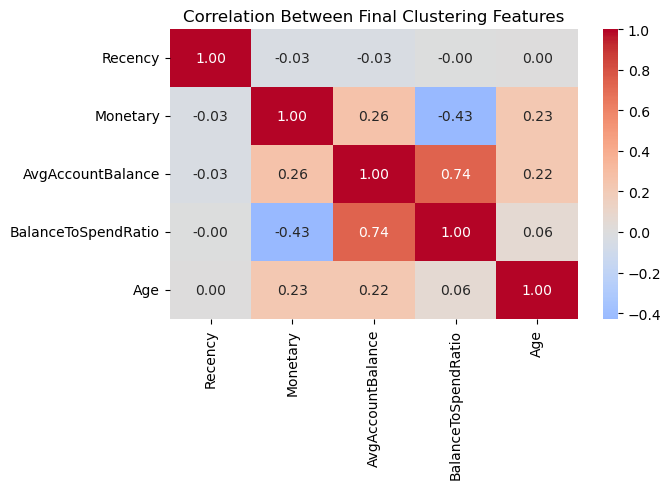

In [20]:
# Drop zero-variance features
zero_variance_features = X_scaled_df.columns[X_scaled_df.std() == 0].tolist()

# Drop one feature from every highly correlated pair (|r| > 0.95)
corr_matrix = X_scaled_df.drop(columns=zero_variance_features).corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
redundant_features = [col for col in upper_triangle.columns if (upper_triangle[col] > 0.95).any()]

final_features = [
    col for col in X_scaled_df.columns
    if col not in zero_variance_features + redundant_features
]

print("Zero-variance features dropped :", zero_variance_features)
print("Redundant features dropped     :", redundant_features)
print("Final clustering features      :", final_features)

# Correlation heatmap of the final features
plt.figure(figsize=(7, 5))
sns.heatmap(X_scaled_df[final_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Final Clustering Features")
plt.tight_layout()
plt.show()

**Observation:** *(write your own 2-3 lines here: which features were dropped and why, and what the heatmap shows about the remaining features.)*

---Clustering Setup---

The dataset has ~750k customers. K-Means scales to this easily, but **Agglomerative clustering needs O(n²) memory** and silhouette / t-SNE are also O(n²), so:

* K-Means is fitted on the **full** dataset.
* Hierarchical clustering, the evaluation metrics and the plots use a **fixed random sample** (same rows for every algorithm, so the comparison is fair).

In [21]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram
import joblib
import os
import time

RANDOM_STATE = 42
HIER_SAMPLE_SIZE = 8000    # rows used for hierarchical clustering + metrics + plots
TSNE_SAMPLE_SIZE = 5000    # rows used for t-SNE (subset of the sample above)
K_RANGE = range(2, 11)     # candidate numbers of clusters

# Final clustering matrix
X_final = X_scaled_df[final_features].values

# One fixed sample shared by ALL algorithms
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = rng.choice(X_final.shape[0], size=HIER_SAMPLE_SIZE, replace=False)
X_sample = X_final[sample_idx]

def evaluate_clustering(X, labels):
    """Return the three mandatory internal validation metrics."""
    if len(np.unique(labels)) < 2:
        return {"Silhouette": np.nan, "Davies-Bouldin": np.nan, "Calinski-Harabasz": np.nan}
    return {
        "Silhouette": silhouette_score(X, labels),                 # higher is better (-1 to 1)
        "Davies-Bouldin": davies_bouldin_score(X, labels),         # lower is better
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),   # higher is better
    }

print("Full matrix  :", X_final.shape)
print("Sample matrix:", X_sample.shape)

Full matrix  : (751222, 5)
Sample matrix: (8000, 5)


---Algorithm 1: K-Means Clustering---

### Choosing k: Elbow curve
K-Means is fitted for k = 2 to 10 on the full dataset. The **elbow curve** plots inertia (within-cluster sum of squares) against k. Silhouette is plotted next to it as a second opinion, because the elbow alone is often ambiguous.

In [22]:
k_results = []
kmeans_models = {}

for k in K_RANGE:
    start = time.time()
    km = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE)
    km.fit(X_final)
    kmeans_models[k] = km

    scores = evaluate_clustering(X_sample, km.labels_[sample_idx])
    k_results.append({"k": k, "Inertia": km.inertia_, **scores})
    print(f"k={k:2d} done in {time.time() - start:5.1f}s")

k_results_df = pd.DataFrame(k_results)
k_results_df

k= 2 done in   5.1s
k= 3 done in   3.3s
k= 4 done in   3.6s
k= 5 done in   3.9s
k= 6 done in   5.3s
k= 7 done in   6.6s
k= 8 done in   8.8s
k= 9 done in  13.3s
k=10 done in   7.9s


,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,2.914319e+06,0.201013,1.759731,2253.568777
1,3,2.397922e+06,0.207925,1.503172,2282.399011
2,4,2.065729e+06,0.226221,1.333763,2174.448196
3,5,1.822069e+06,0.219844,1.294276,2122.374945
4,6,1.678097e+06,0.201370,1.296737,1979.214303
5,7,1.563931e+06,0.211824,1.304652,1885.145549
6,8,1.465742e+06,0.197390,1.325145,1787.082215
7,9,1.380636e+06,0.203411,1.288773,1722.800795
8,10,1.312233e+06,0.201057,1.292993,1653.577873


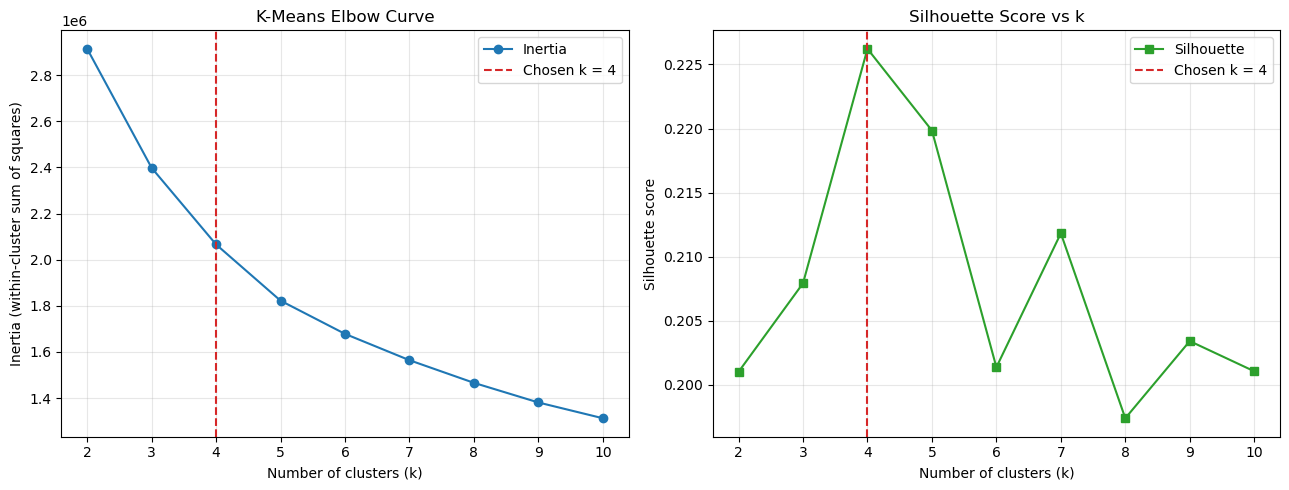

Chosen k: 4


In [23]:
# Default choice = k with the highest silhouette score (k = 2 often wins on silhouette alone,
# but 3-5 segments are usually more useful for customers).
# Look at the plots below and OVERRIDE this if you prefer a different k, e.g. optimal_k = 4
optimal_k = int(k_results_df.loc[k_results_df["Silhouette"].idxmax(), "k"])
# optimal_k = 4

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow curve
axes[0].plot(k_results_df["k"], k_results_df["Inertia"], marker="o", color="tab:blue", label="Inertia")
axes[0].axvline(optimal_k, color="tab:red", linestyle="--", label=f"Chosen k = {optimal_k}")
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Silhouette vs k
axes[1].plot(k_results_df["k"], k_results_df["Silhouette"], marker="s", color="tab:green", label="Silhouette")
axes[1].axvline(optimal_k, color="tab:red", linestyle="--", label=f"Chosen k = {optimal_k}")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("Chosen k:", optimal_k)

**Observation:** *(write your own justification of k: where does the elbow bend, what does the silhouette curve say, do they agree, and does the chosen k make business sense?)*

In [24]:
# Final K-Means model (more initialisations than in the search loop)
kmeans_final = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans_final.fit_predict(X_final)

customer_features["KMeans_Cluster"] = kmeans_labels

print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index().to_string())

K-Means cluster sizes:
0    155910
1    208951
2    251568
3    134793


---Algorithm 2: Agglomerative Hierarchical Clustering---

### Dendrogram
The dendrogram is built with Ward linkage on the shared sample (truncated to the last 30 merged clusters so it stays readable). The dashed red line is the cut that gives the chosen number of clusters.

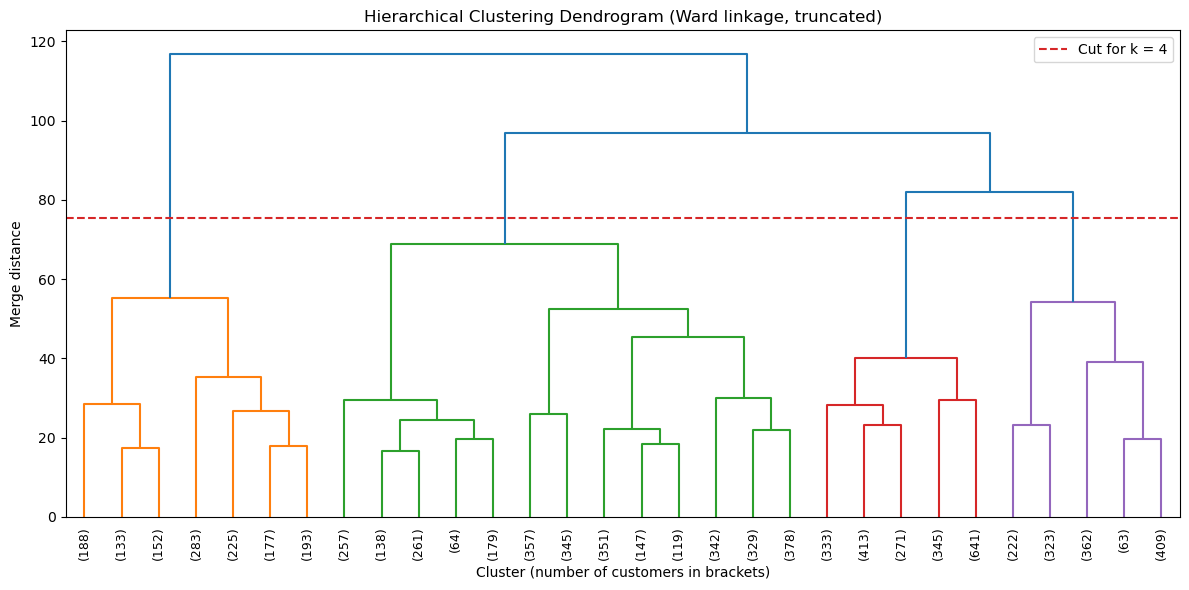

In [25]:
Z = linkage(X_sample, method="ward")

# Height at which the tree is cut to obtain `optimal_k` clusters
cut_height = (Z[-(optimal_k - 1), 2] + Z[-optimal_k, 2]) / 2

plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9, show_leaf_counts=True)
plt.axhline(cut_height, color="tab:red", linestyle="--", label=f"Cut for k = {optimal_k}")
plt.title("Hierarchical Clustering Dendrogram (Ward linkage, truncated)")
plt.xlabel("Cluster (number of customers in brackets)")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()

**Observation:** *(write your own reading of the dendrogram: where are the big jumps in merge distance, and does it support the k chosen with K-Means?)*

### Comparing linkage strategies
Agglomerative clustering is fitted with four linkage criteria on the same sample and the same k, and scored with the three mandatory metrics.

In [26]:
linkage_methods = ["ward", "complete", "average", "single"]
agglo_labels = {}
agglo_rows = []

for method in linkage_methods:
    start = time.time()
    model = AgglomerativeClustering(n_clusters=optimal_k, linkage=method)
    labels = model.fit_predict(X_sample)
    agglo_labels[method] = labels

    scores = evaluate_clustering(X_sample, labels)
    sizes = pd.Series(labels).value_counts().sort_index().tolist()
    agglo_rows.append({
        "Algorithm": f"Agglomerative ({method})",
        **scores,
        "Smallest cluster (%)": min(sizes) / len(labels) * 100,
        "Cluster sizes": sizes
    })
    print(f"{method:9s} done in {time.time() - start:5.1f}s")

linkage_comparison = pd.DataFrame(agglo_rows)
linkage_comparison

ward      done in   3.4s
complete  done in   3.5s
average   done in   3.6s
single    done in   1.7s


,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster (%),Cluster sizes
0,Agglomerative (ward),0.136106,1.629268,1612.169442,16.8875,"[3267, 1351, 1379, 2003]"
1,Agglomerative (complete),0.132030,1.745281,1433.597465,8.4000,"[3051, 2256, 2021, 672]"
2,Agglomerative (average),0.153691,1.228075,668.792438,0.1500,"[1441, 54, 6493, 12]"
3,Agglomerative (single),0.213179,0.502147,3.687287,0.0125,"[7997, 1, 1, 1]"


**Observation:** *(write your own comparison of the linkages. Look at the cluster sizes and the "Smallest cluster (%)" column: single/average linkage often produce one giant cluster plus a few tiny ones, which can inflate silhouette / Davies-Bouldin without giving useful segments. Is that what you see?)*

In [27]:
# Best linkage = highest silhouette among NON-degenerate solutions.
# Single/average linkage often score a high silhouette by isolating a handful of outliers
# in tiny clusters, which is useless for segmentation, so solutions whose smallest
# cluster holds < 1% of the sample are excluded.
MIN_CLUSTER_SHARE = 1.0   # percent

valid = linkage_comparison[linkage_comparison["Smallest cluster (%)"] >= MIN_CLUSTER_SHARE]
if valid.empty:           # fall back to all linkages if every one is degenerate
    valid = linkage_comparison

best_linkage = valid.loc[valid["Silhouette"].idxmax(), "Algorithm"].split("(")[1].rstrip(")")

print("Linkages with a tiny cluster (< 1% of sample):",
      linkage_comparison.loc[linkage_comparison["Smallest cluster (%)"] < MIN_CLUSTER_SHARE, "Algorithm"].tolist())
print("Best linkage:", best_linkage)

Linkages with a tiny cluster (< 1% of sample): ['Agglomerative (average)', 'Agglomerative (single)']
Best linkage: ward


---Evaluation: Metric Comparison---

All algorithms are scored on the **same sample** with the three mandatory metrics:

| Metric | Better when |
|---|---|
| Silhouette Score | higher (range -1 to 1) |
| Davies-Bouldin Index | lower |
| Calinski-Harabasz Index | higher |

In [28]:
# K-Means labels restricted to the shared sample
kmeans_sample_labels = kmeans_labels[sample_idx]

kmeans_row = {
    "Algorithm": "K-Means",
    **evaluate_clustering(X_sample, kmeans_sample_labels),
    "Smallest cluster (%)": pd.Series(kmeans_sample_labels).value_counts().min() / len(kmeans_sample_labels) * 100,
    "Cluster sizes": pd.Series(kmeans_sample_labels).value_counts().sort_index().tolist()
}

results_df = pd.concat([pd.DataFrame([kmeans_row]), linkage_comparison], ignore_index=True)
results_df = results_df.sort_values("Silhouette", ascending=False).reset_index(drop=True)

print(f"Number of clusters: {optimal_k} | Evaluation sample: {HIER_SAMPLE_SIZE} customers\n")
results_df.style.format({
    "Silhouette": "{:.4f}",
    "Davies-Bouldin": "{:.4f}",
    "Smallest cluster (%)": "{:.2f}",
    "Calinski-Harabasz": "{:,.1f}"
}).highlight_max(subset=["Silhouette", "Calinski-Harabasz"], color="#b7e4c7") \
  .highlight_min(subset=["Davies-Bouldin"], color="#b7e4c7")

Number of clusters: 4 | Evaluation sample: 8000 customers



,Algorithm,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster (%),Cluster sizes
0,K-Means,0.2262,1.3338,"2,174.4",17.81,"[1636, 2178, 2761, 1425]"
1,Agglomerative (single),0.2132,0.5021,3.7,0.01,"[7997, 1, 1, 1]"
2,Agglomerative (average),0.1537,1.2281,668.8,0.15,"[1441, 54, 6493, 12]"
3,Agglomerative (ward),0.1361,1.6293,"1,612.2",16.89,"[3267, 1351, 1379, 2003]"
4,Agglomerative (complete),0.1320,1.7453,"1,433.6",8.40,"[3051, 2256, 2021, 672]"


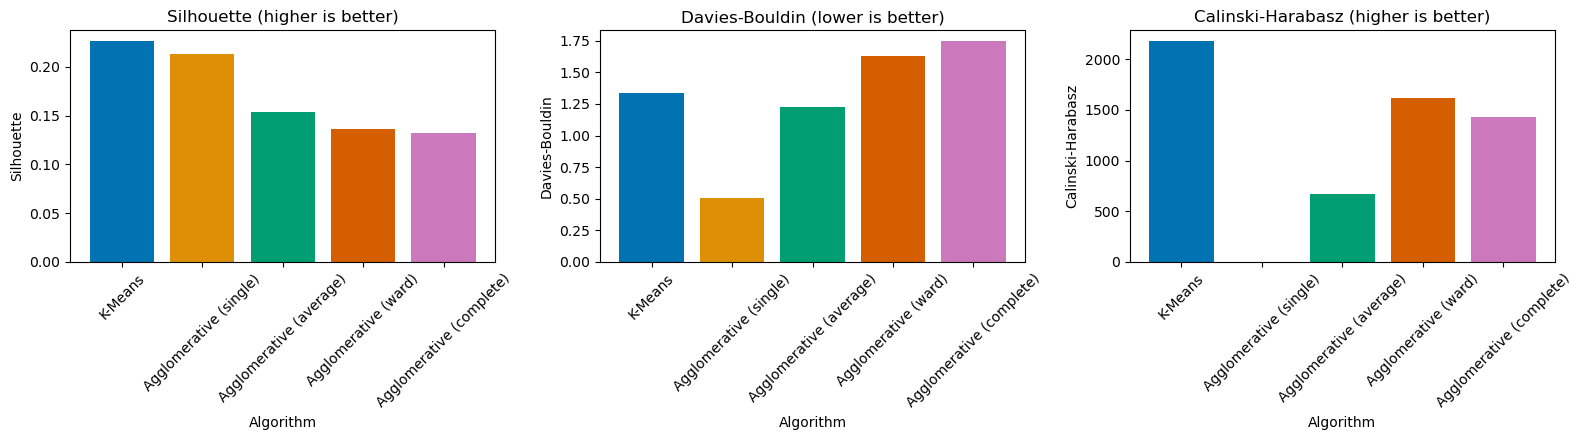

In [29]:
# Visual comparison of the metrics
metrics_to_plot = ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz"]
directions = ["higher is better", "lower is better", "higher is better"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
palette = sns.color_palette("colorblind", len(results_df))

for ax, metric, direction in zip(axes, metrics_to_plot, directions):
    ax.bar(results_df["Algorithm"], results_df[metric], color=palette)
    ax.set_title(f"{metric} ({direction})")
    ax.set_xlabel("Algorithm")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Observation:** *(write your own interpretation: which algorithm wins on each metric, do the three metrics agree, and what trade-offs do you see?)*

---Cluster Visualisation: PCA (2 components)---

PCA is fitted on the full feature matrix and the shared sample is projected onto the first two components. The same projection is used for every algorithm so the colourings are directly comparable.

Variance explained: PC1 = 35.8%, PC2 = 28.2%, total = 64.0%


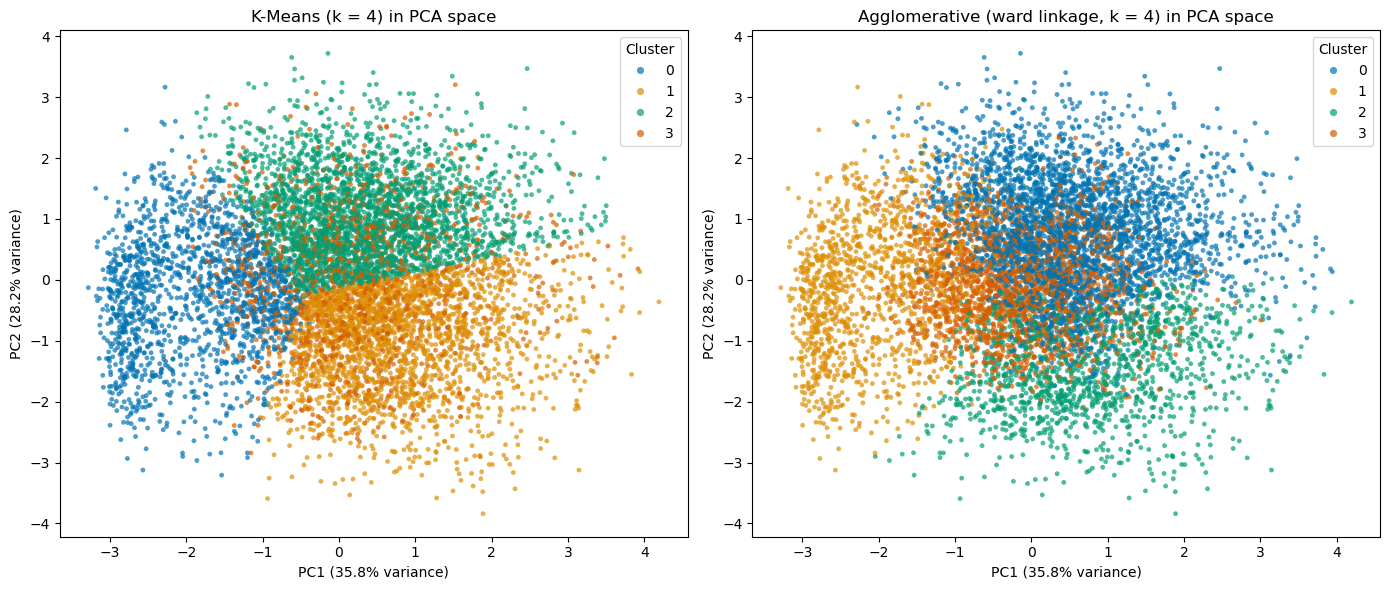

In [30]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca.fit(X_final)
X_sample_pca = pca.transform(X_sample)

explained = pca.explained_variance_ratio_ * 100
print(f"Variance explained: PC1 = {explained[0]:.1f}%, PC2 = {explained[1]:.1f}%, total = {explained.sum():.1f}%")

def plot_pca_clusters(ax, labels, title):
    sns.scatterplot(
        x=X_sample_pca[:, 0], y=X_sample_pca[:, 1],
        hue=labels, palette="colorblind", s=12, alpha=0.7, linewidth=0, ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({explained[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({explained[1]:.1f}% variance)")
    ax.legend(title="Cluster", loc="best", markerscale=1.5)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_pca_clusters(axes[0], kmeans_sample_labels, f"K-Means (k = {optimal_k}) in PCA space")
plot_pca_clusters(axes[1], agglo_labels[best_linkage], f"Agglomerative ({best_linkage} linkage, k = {optimal_k}) in PCA space")
plt.tight_layout()
plt.show()

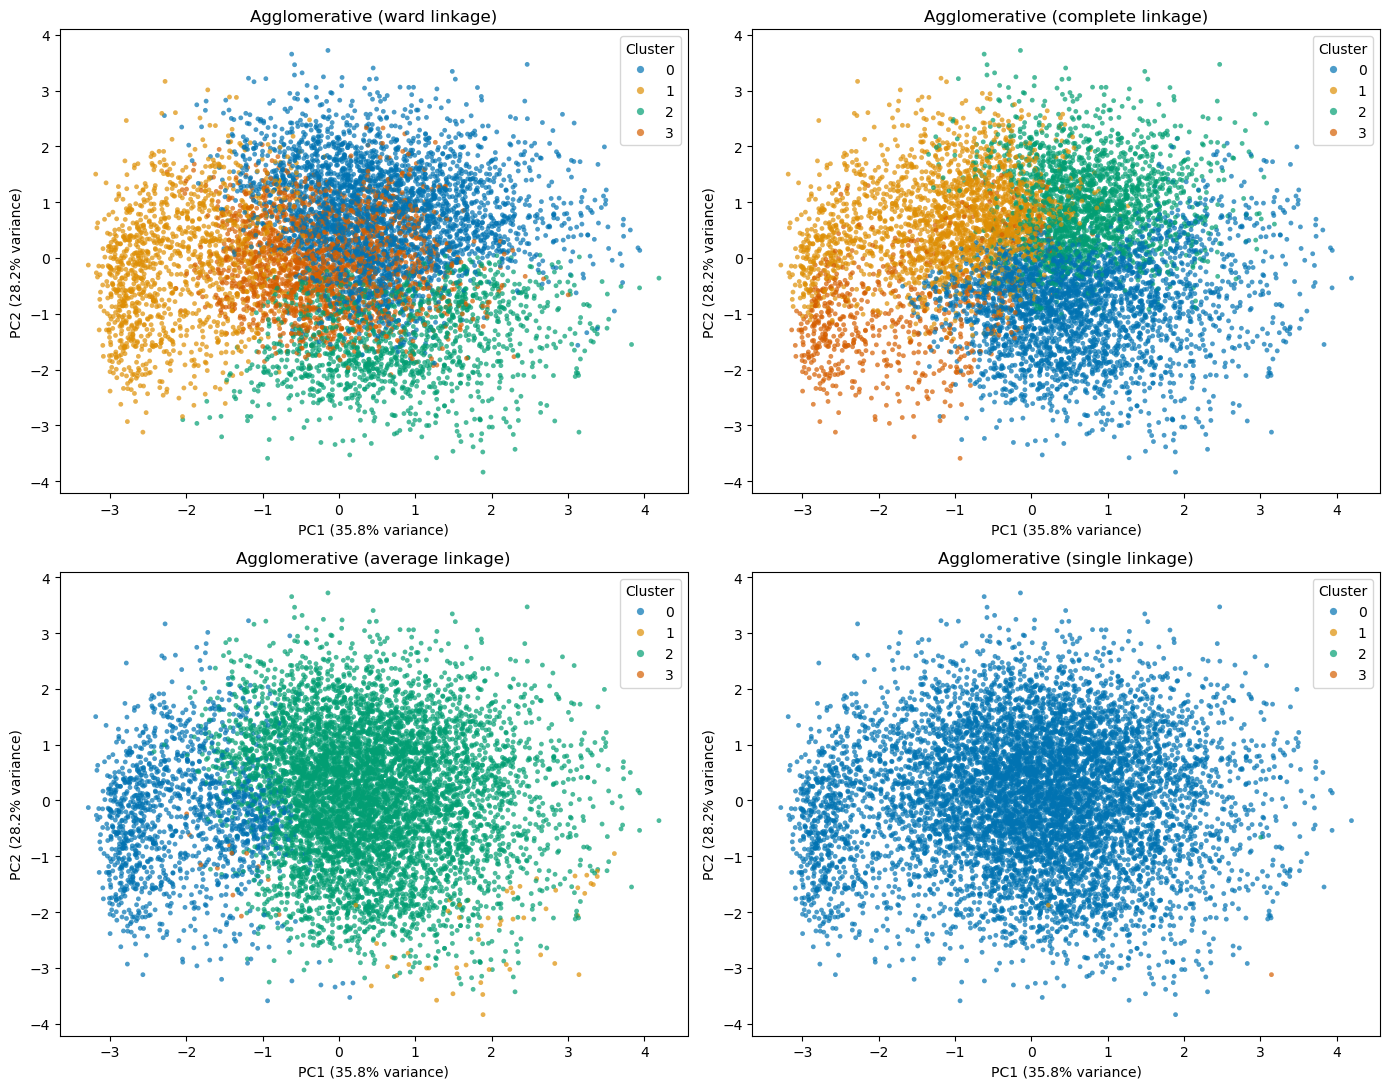

In [31]:
# All four linkage strategies in PCA space
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, method in zip(axes.ravel(), linkage_methods):
    plot_pca_clusters(ax, agglo_labels[method], f"Agglomerative ({method} linkage)")
plt.tight_layout()
plt.show()

**Observation:** *(write your own reading of the PCA plots: do the clusters separate or overlap, how much variance do 2 components capture, and do both algorithms find similar structure?)*

---Cluster Visualisation: t-SNE---

t-SNE is computed once on a smaller subset and coloured by both algorithms. It preserves local neighbourhoods better than PCA, but distances between far-apart blobs are not meaningful.

t-SNE finished in 25.5s


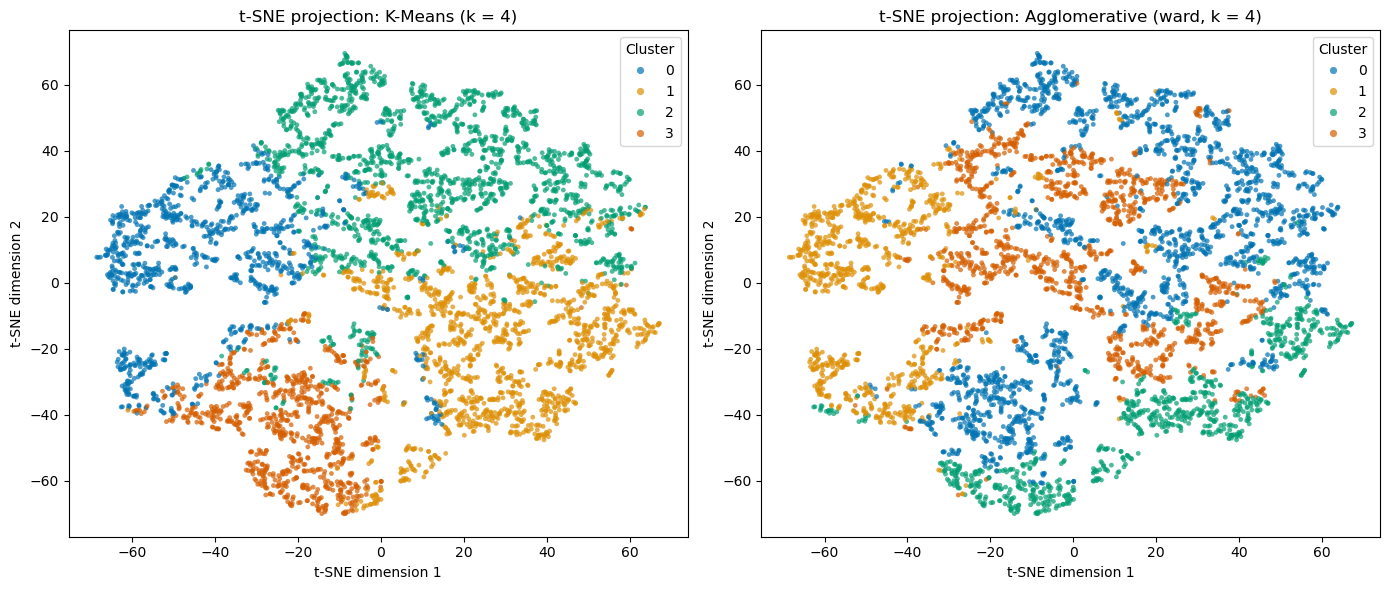

In [32]:
tsne_X = X_sample[:TSNE_SAMPLE_SIZE]

start = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(tsne_X)
print(f"t-SNE finished in {time.time() - start:.1f}s")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, labels, title in zip(
    axes,
    [kmeans_sample_labels[:TSNE_SAMPLE_SIZE], agglo_labels[best_linkage][:TSNE_SAMPLE_SIZE]],
    [f"K-Means (k = {optimal_k})", f"Agglomerative ({best_linkage}, k = {optimal_k})"]
):
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=labels, palette="colorblind",
                    s=12, alpha=0.7, linewidth=0, ax=ax)
    ax.set_title(f"t-SNE projection: {title}")
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    ax.legend(title="Cluster", loc="best", markerscale=1.5)

plt.tight_layout()
plt.show()

**Observation:** *(write your own comparison of t-SNE vs PCA: does t-SNE reveal tighter or more separated groups?)*

---Cluster Profiling (K-Means)---

Clustering has no ground-truth labels here, so the clusters are validated by profiling them: average value of each feature per cluster, in original units and as standardised z-scores.

,Customers,Share (%),Recency,Monetary,AvgTransactionAmount,AvgAccountBalance,BalanceToSpendRatio,Age
KMeans_Cluster,,,,,,,,
0,155910,20.8,121.68,967.93,900.29,1731.51,4.59,27.13
1,208951,27.8,99.80,198.06,185.21,88741.97,1303.69,27.06
2,251568,33.5,92.19,2902.79,2404.99,109142.18,78.17,31.60
3,134793,17.9,264.78,1248.89,1207.21,76130.88,205.77,29.35


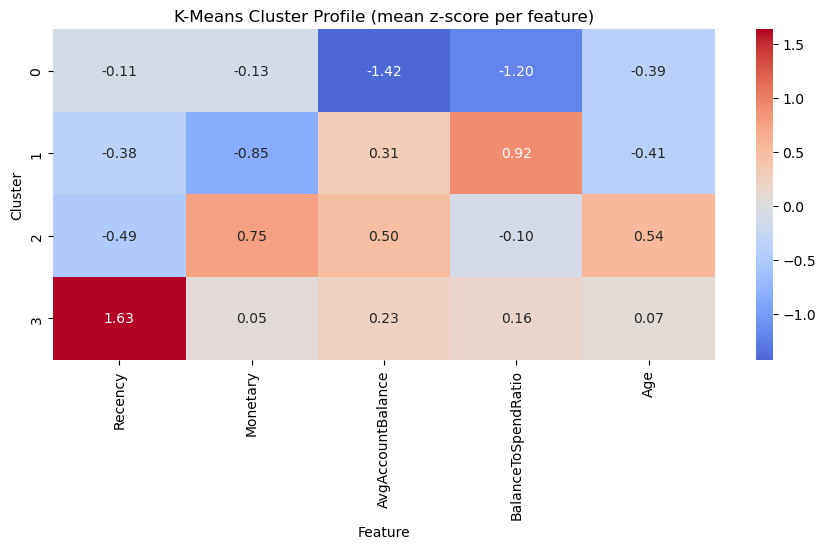

In [33]:
profile_columns = ["Recency", "Monetary", "AvgTransactionAmount", "AvgAccountBalance",
                   "BalanceToSpendRatio", "Age"]
profile_columns = [c for c in profile_columns if c in customer_features.columns]

# Original-scale profile
cluster_profile = customer_features.groupby("KMeans_Cluster")[profile_columns].mean().round(2)
cluster_profile.insert(0, "Customers", customer_features["KMeans_Cluster"].value_counts().sort_index())
cluster_profile.insert(1, "Share (%)", (cluster_profile["Customers"] / len(customer_features) * 100).round(1))
display(cluster_profile)

# Standardised profile as a heatmap (which features define each cluster)
zscore_profile = (
    pd.DataFrame(X_final, columns=final_features)
    .groupby(kmeans_labels).mean()
)

plt.figure(figsize=(9, 0.9 * optimal_k + 2))
sns.heatmap(zscore_profile, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("K-Means Cluster Profile (mean z-score per feature)")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

**Cluster interpretation:** *(write your own segment names and descriptions, e.g. "Cluster 0 - ...: high balance, low spend ...". Base them on the table and heatmap above.)*

---Save Results---

In [34]:
# Results table + customers with their cluster labels
results_df.drop(columns=["Cluster sizes"]).to_csv("clustering_results_summary.csv", index=False)
customer_features.to_csv("bank_customer_clusters.csv", index=False)

# Trained models (repo layout expects a models/ folder next to notebooks/)
os.makedirs("../models", exist_ok=True)
joblib.dump(scaler, "../models/clustering_scaler.pkl")
joblib.dump(kmeans_final, "../models/kmeans_final.pkl")
joblib.dump(pca, "../models/clustering_pca.pkl")

print("Saved: clustering_results_summary.csv, bank_customer_clusters.csv")
print("Saved models to ../models/")

Saved: clustering_results_summary.csv, bank_customer_clusters.csv
Saved models to ../models/


---Conclusion---

*(write your own 4-6 lines: final k, best algorithm and why (cite the three metrics), the customer segments found, and one limitation, e.g. hierarchical clustering was run on a sample of 8,000 customers because of O(n²) memory.)*

In [35]:
# # Run this after the clustering notebook's final model cell.
# import joblib, os, numpy as np, pandas as pd
# os.makedirs("../models", exist_ok=True)

# # `scaler` was fitted on clustering_features, before zero-variance/correlation removal.
# # `final_features` are the selected scaled columns used to fit kmeans_final.
# base_features = list(clustering_features)
# selected_features = list(final_features)
# # KMeans expects only the selected columns, so wrap scaling and selection in a pipeline-like bundle.
# joblib.dump({
#     "scaler": scaler,
#     "model": kmeans_final,
#     "features": selected_features,
#     "base_features": base_features,
#     "defaults": {c: float(customer_features[c].median()) for c in base_features if c in customer_features.columns},
#     "cluster_names": {str(int(i)): f"Customer segment {int(i)+1}" for i in range(kmeans_final.n_clusters)},
# }, "../models/clustering_bundle.joblib", compress=3)
# print("Saved ../models/clustering_bundle.joblib")


Saved ../models/clustering_bundle.joblib
